# PhishGuard-ML: 01 - Exploratory Data Analysis (EDA)

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
import os

## 1. Dataset and Download

In [6]:
# Fetch dataset from UCI
dataset = fetch_ucirepo(id=327)

X = dataset.data.features
y = dataset.data.targets

df = pd.concat([X, y], axis=1)

# The original Result target uses: -1 = phishing, 1 = legitimate
# Remap it so phishing is the positive class (1 = phishing, 0 = legitimate)
df.rename(columns={"result": "Result"}, inplace=True)
df["Result"] = (df["Result"] == -1).astype(int)

# Save to data directory
os.makedirs("data", exist_ok=True)
df.to_csv("data/phishing_websites.csv", index=False)

print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (11055, 31)


,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,0


## 2. Data Inspection

In [7]:
print("--- Head ---")
print(df.head())
print("\n--- Tail ---")
print(df.tail())
print("\n--- Shape ---")
print(df.shape)
print("\n--- Describe ---")
print(df.describe())
print("\n--- Info ---")
df.info()

print("\nTotal missing values:", df.isnull().sum().sum())
print("Total duplicated rows:", df.duplicated().sum())

--- Head ---
   having_ip_address  url_length  shortining_service  having_at_symbol  \
0                 -1           1                   1                 1   
1                  1           1                   1                 1   
2                  1           0                   1                 1   
3                  1           0                   1                 1   
4                  1           0                  -1                 1   

   double_slash_redirecting  prefix_suffix  having_sub_domain  sslfinal_state  \
0                        -1             -1                 -1              -1   
1                         1             -1                  0               1   
2                         1             -1                 -1              -1   
3                         1             -1                 -1              -1   
4                         1             -1                  1               1   

   domain_registration_length  favicon  ...  popupwindo

## 3. EDA Visualizations

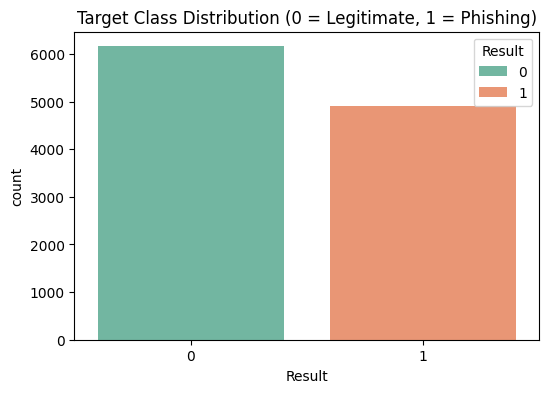

In [8]:
# Target class distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Result', hue='Result', palette='Set2')
plt.title('Target Class Distribution (0 = Legitimate, 1 = Phishing)')
plt.show()

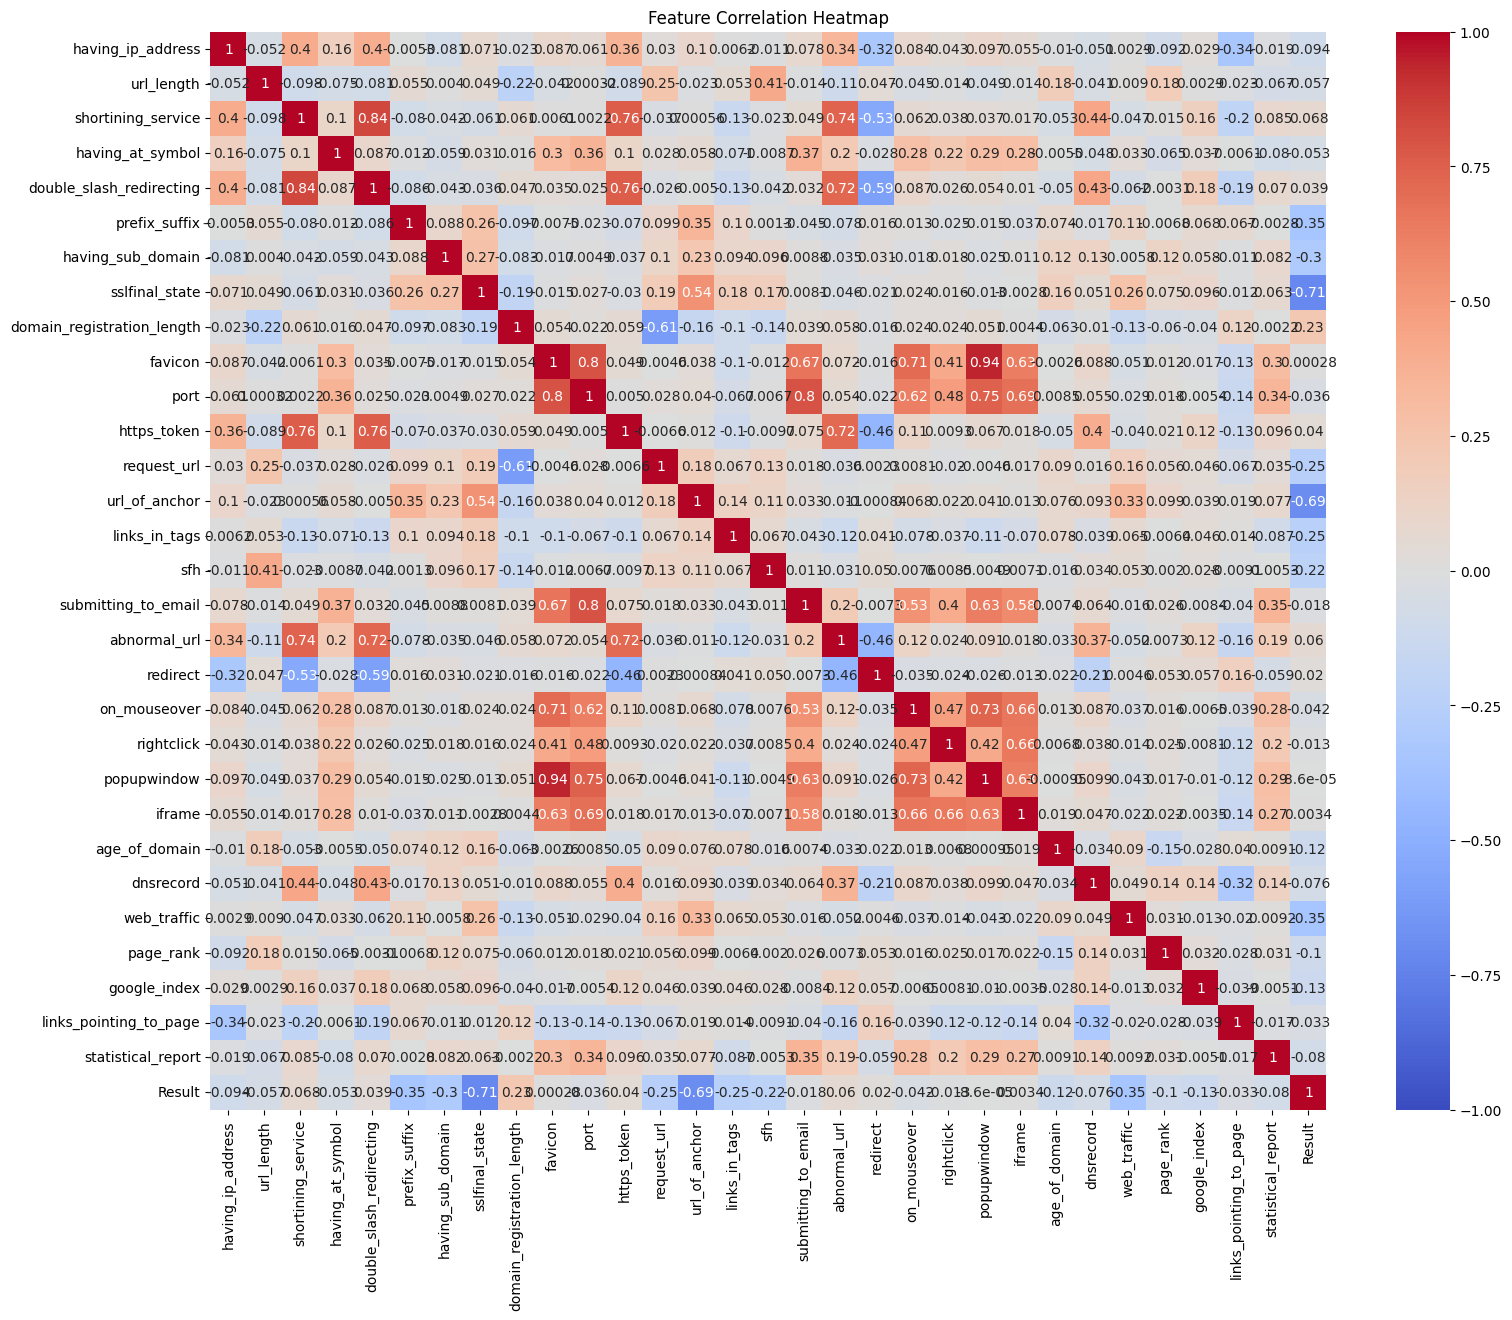

In [ ]:
# Feature correlation heatmap
plt.figure(figsize=(18, 14))
corr = df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Feature Correlation Heatmap')
plt.show()

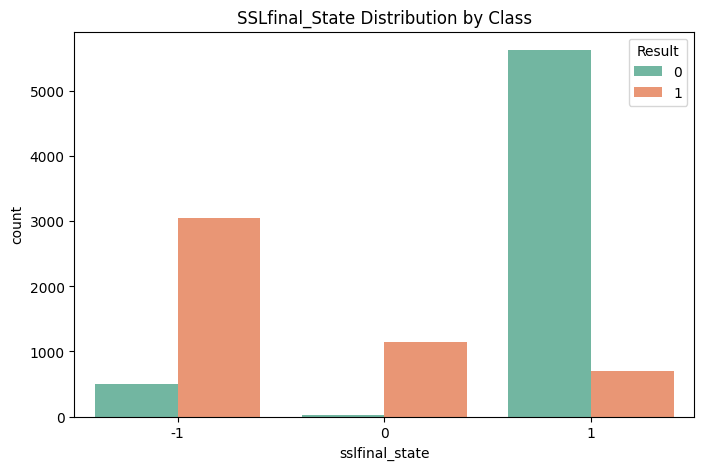

In [12]:
# Feature distributions by class (Example: SSLfinal_State)
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='sslfinal_state', hue='Result', palette='Set2')
plt.title('SSLfinal_State Distribution by Class')
plt.show()

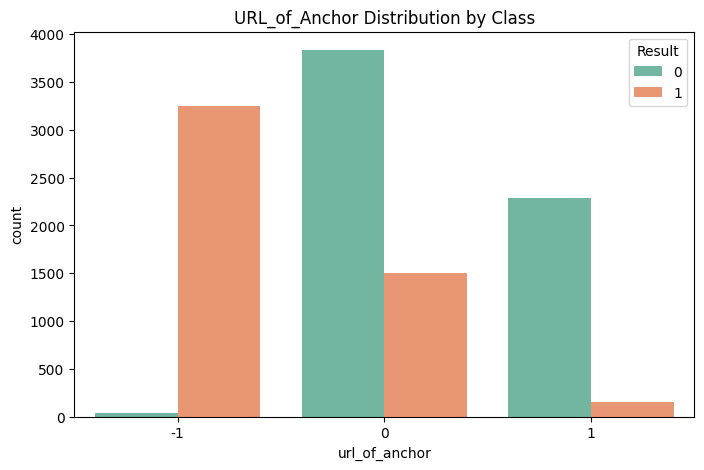

In [13]:
# Feature distributions by class (Example: URL_of_Anchor)
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='url_of_anchor', hue='Result', palette='Set2')
plt.title('URL_of_Anchor Distribution by Class')
plt.show()